# 02 - Returns & Volatility

Understand the **statistical behaviour** of ETHUSDT daily returns.

Covers:

1. Daily returns
2. Distribution (histogram, moments)
3. Rolling volatility (annualized)
4. Drawdown
5. Rolling Sharpe
6. Monthly / yearly return tables
7. Summary stats


## Setup

In [11]:
# --- setup --------------------------------------------------------
import sys
# Project paths on your two systems
from pathlib import Path

# Project paths on your two systems
PROJECT_PATHS = [
    Path(r"D:\Projects\done\eth_bot\eth_bot_v2"),
    Path(r"D:\Sachin Chakrawarti\eth_bot\eth_bot_v2"),
]

# Automatically select the project path that exists
for project_path in PROJECT_PATHS:
    if project_path.exists():
        sys.path.insert(0, str(project_path))
        break
else:
    raise FileNotFoundError(
        "eth_bot_v2 project directory was not found on this system."
    )

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analysis.loader import load_ohlcv
from analysis import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.figsize"] = (12, 4)

df = load_ohlcv()
close = df.close
r = close.pct_change().dropna()
print(f"days: {len(df)}   returns: {len(r)}")
print(f"range: {r.index.min().date()} -> {r.index.max().date()}")

days: 2191   returns: 2190
range: 2020-10-06 -> 2026-10-04


## 1. Daily returns

Simple percent change of close-to-close.

In [12]:
r.tail(10).to_frame("return")

,return
date,
2026-09-25,0.001324
2026-09-26,0.001754
2026-09-27,-0.002848
2026-09-28,0.000022
2026-09-29,-0.003991
2026-09-30,0.002999
2026-10-01,0.007599
2026-10-02,-0.013978
2026-10-03,0.006985


## 2. Return distribution

Crypto daily returns are famously **fat-tailed** and slightly **negatively skewed**.

- kurtosis > 3 → fatter tails than normal
- skew < 0   → bigger crashes than rallies

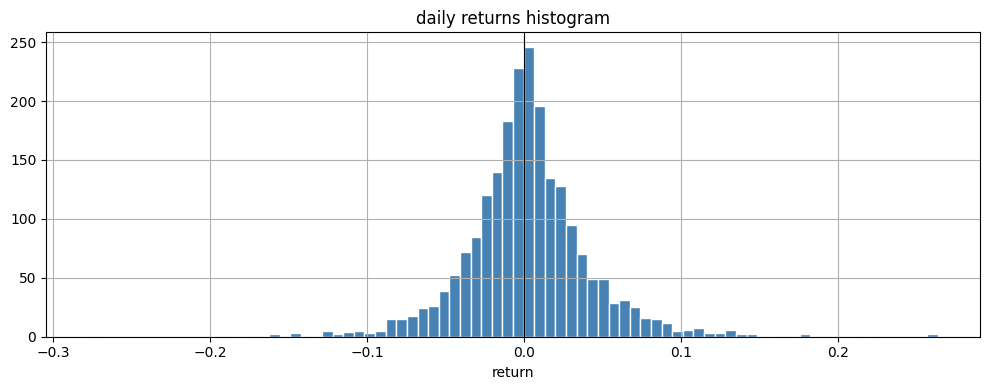

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
r.hist(bins=80, ax=ax, color="steelblue", edgecolor="white")
ax.axvline(0, color="black", lw=0.8)
ax.set_title("daily returns histogram")
ax.set_xlabel("return")
plt.tight_layout()
plt.show()

In [14]:
print(f"mean       {r.mean(): .6f}")
print(f"std        {r.std(ddof=0): .6f}")
print(f"skew       {r.skew(): .4f}")
print(f"kurtosis   {r.kurtosis(): .4f}")
print(f"min        {r.min(): .4f}")
print(f"max        {r.max(): .4f}")
print(f"P(>|5%|)   {(r.abs() > 0.05).mean():.2%}")

mean        0.001745
std         0.040350
skew        0.2491
kurtosis    5.0280
min        -0.2774
max         0.2633
P(>|5%|)   16.12%


## 3. Rolling volatility

30-day standard deviation of returns, annualized by multiplying
by sqrt(365).

- Low vol (green zone) → calm markets, trend-following works
- High vol (red zone) → choppy, mean reversion works

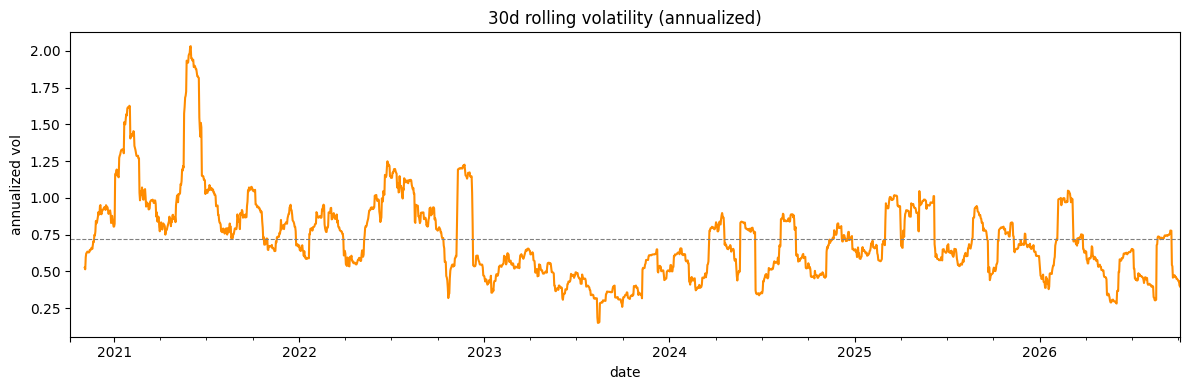

mean vol 30d: 72.16%
min  vol 30d: 14.94%
max  vol 30d: 203.26%


In [15]:
vol30 = r.rolling(30).std() * np.sqrt(365)

fig, ax = plt.subplots(figsize=(12, 4))
vol30.plot(ax=ax, color="darkorange", title="30d rolling volatility (annualized)")
ax.axhline(vol30.mean(), ls="--", lw=0.8, color="gray")
ax.set_ylabel("annualized vol")
plt.tight_layout()
plt.show()

print(f"mean vol 30d: {vol30.mean():.2%}")
print(f"min  vol 30d: {vol30.min():.2%}")
print(f"max  vol 30d: {vol30.max():.2%}")

## 4. Drawdown

Percent decline from the running peak.

- **Max drawdown** = worst peak-to-trough loss
- This is what an investor *feels*. Usually much larger than vol suggests.

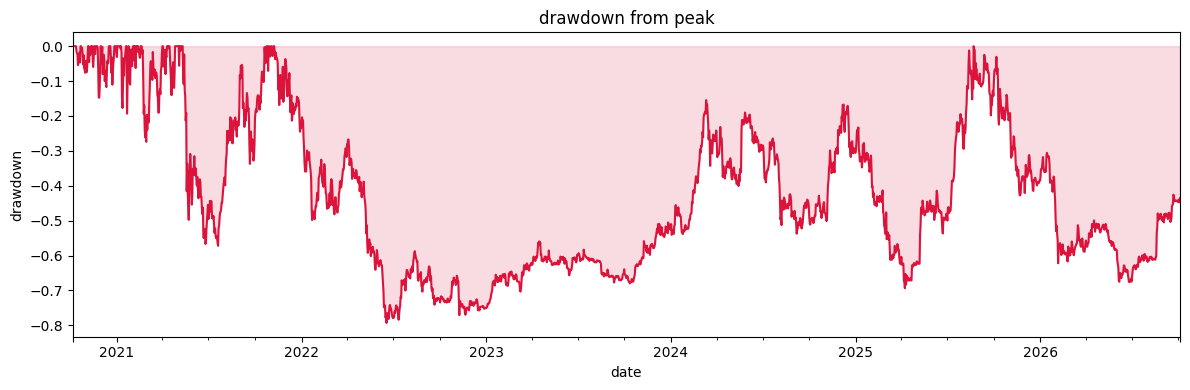

max drawdown : -79.30%
when         : 2022-06-18


In [16]:
cum = (1 + r).cumprod()
peak = cum.cummax()
dd = cum / peak - 1

fig, ax = plt.subplots(figsize=(12, 4))
dd.plot(ax=ax, color="crimson", title="drawdown from peak")
ax.fill_between(dd.index, dd, 0, color="crimson", alpha=0.15)
ax.set_ylabel("drawdown")
plt.tight_layout()
plt.show()

print(f"max drawdown : {dd.min():.2%}")
print(f"when         : {dd.idxmin().date()}")

## 5. Rolling Sharpe (180d)

Sharpe = mean(return) / std(return), annualized.

Positive Sharpe = you were paid for the risk over that window.
Negative Sharpe = the window destroyed risk-adjusted value.

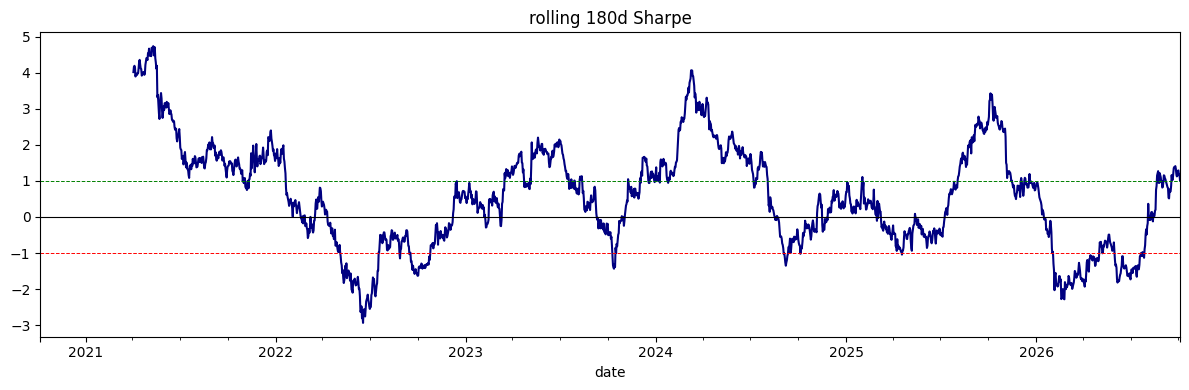

In [17]:
sharpe180 = (r.rolling(180).mean() / r.rolling(180).std(ddof=0)) * np.sqrt(365)

fig, ax = plt.subplots(figsize=(12, 4))
sharpe180.plot(ax=ax, color="navy", title="rolling 180d Sharpe")
ax.axhline(0, color="black", lw=0.8)
ax.axhline(1, ls="--", color="green", lw=0.7)
ax.axhline(-1, ls="--", color="red", lw=0.7)
plt.tight_layout()
plt.show()

## 6. Monthly returns

Each cell shows the % return for that month.
Green = up month, red = down month.

In [18]:
monthly = (1 + r).resample("M").prod() - 1
pivot = pd.DataFrame({
    "year":  monthly.index.year,
    "month": monthly.index.month,
    "ret":   monthly.values,
}).pivot(index="year", columns="month", values="ret")

pivot.columns = ["Jan","Feb","Mar","Apr","May","Jun",
                 "Jul","Aug","Sep","Oct","Nov","Dec"]

def color(v):
    if pd.isna(v): return ""
    return f"background-color: {'#d4f4d4' if v > 0 else '#f4d4d4'}"

pivot.style.format("{:+.1%}").map(color)

C:\Users\srgi\AppData\Local\Temp\ipykernel_35016\131724264.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly = (1 + r).resample("M").prod() - 1


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
2020,+nan%,+nan%,+nan%,+nan%,+nan%,+nan%,+nan%,+nan%,+nan%,+9.3%,+59.6%,+19.4%
2021,+78.2%,+8.1%,+35.2%,+44.4%,-2.4%,-15.9%,+11.2%,+35.5%,-12.5%,+42.9%,+8.0%,-20.6%
2022,-26.9%,+8.7%,+12.3%,-16.9%,-28.8%,-44.8%,+56.7%,-7.4%,-14.5%,+18.4%,-17.7%,-7.6%
2023,+32.5%,+1.3%,+13.5%,+2.7%,+0.2%,+3.2%,-4.0%,-11.3%,+1.5%,+8.6%,+13.1%,+11.2%
2024,+0.1%,+46.3%,+9.1%,-17.3%,+24.8%,-8.6%,-6.0%,-22.3%,+3.6%,-3.2%,+47.0%,-9.9%
2025,-1.1%,-32.2%,-18.6%,-1.6%,+40.9%,-1.7%,+48.8%,+18.7%,-5.6%,-7.2%,-22.3%,-0.7%
2026,-17.5%,-19.9%,+7.2%,+7.2%,-11.1%,-21.7%,+18.5%,+32.5%,+8.8%,+1.5%,+nan%,+nan%


## 7. Yearly returns

In [19]:
yearly = (1 + r).resample("Y").prod() - 1
yearly.index = yearly.index.year
yearly.to_frame("return").style.format("{:+.1%}")

C:\Users\srgi\AppData\Local\Temp\ipykernel_35016\2198966888.py:1: FutureWarning: 'Y' is deprecated and will be removed in a future version, please use 'YE' instead.
  yearly = (1 + r).resample("Y").prod() - 1


,return
date,
2020,+108.3%
2021,+399.2%
2022,-67.5%
2023,+90.8%
2024,+46.3%
2025,-11.0%
2026,-8.2%


## 8. Biggest single days

Top 5 up and top 5 down — useful for sanity checks.

In [20]:
top_up = r.nlargest(5).to_frame("return")
top_dn = r.nsmallest(5).to_frame("return")
print("UP")
print(top_up.to_string(formatters={"return": "{:+.2%}".format}))
print("\nDOWN")
print(top_dn.to_string(formatters={"return": "{:+.2%}".format}))

UP
            return
date              
2021-05-24 +26.33%
2021-01-03 +26.30%
2025-05-08 +21.88%
2024-05-20 +19.23%
2022-07-18 +18.11%

DOWN
            return
date              
2021-05-19 -27.74%
2021-01-21 -19.32%
2022-11-09 -17.38%
2021-06-21 -15.96%
2022-06-13 -15.68%


## 9. Summary statistics

Everything in one dict, computed by `analysis.stats.summary()`.

In [21]:
s = stats.summary(close)
for k, v in s.items():
    if isinstance(v, float) and abs(v) < 10:
        print(f"  {k:<14} {v: .4f}")
    else:
        print(f"  {k:<14} {v}")

  start          2020-10-05
  end            2026-10-04
  days           2191
  total_return    6.7115
  ann_vol         0.7709
  sharpe          0.8264
  max_drawdown   -0.7930
  best_day        0.2633
  worst_day      -0.2774


## Next steps

- **Gap check** → `03_data_quality.ipynb`
- **Cross-source** → `04_funding_oi.ipynb`
- **Automated report** → `python -m analysis.reports` writes
  the same stats to `reports/daily/YYYY-MM-DD/summary.md`
